# Diviser pour régner — Exercice 8 : la paire de points la plus proche (correction)

Ce notebook contient, pour chaque question, trois blocs **toujours séparés** :

| Bloc | Contenu |
|:---|:---|
| 📝 **ÉNONCÉ** | la question, recopiée du sujet |
| ✅ **RÉSOLUTION** | la réponse attendue (code et/ou texte) |
| 💡 **EXPLICATION PÉDAGOGIQUE** | pourquoi ça marche, le lien avec le cours, les erreurs à éviter. **N'est pas à recopier.** |

**Notions travaillées :** distance entre deux points, double boucle, coût quadratique, tri avec `key`, récursivité, coût en $n\log(n)$.

Exécuter les cellules **dans l'ordre** (*Cell → Run All*).

Pour comparer les méthodes, on compte les appels à `distance` avec une variable globale `nb_appels` (non demandé).

---
# EXERCICE 8

#### 📝 ÉNONCÉ

> Étant donnés n points du plan, on cherche à déterminer quelle est la plus petite distance entre deux de ces points.
> On supposera dans la suite que les points sont donnés sous la forme d'un tableau de tuples.
> En particulier, le code ci-dessous permet de générer une liste de 1000 points dont les coordonnées sont tirées au hasard dans l'intervalle $[0 ; 10^9]$.
> ```python
> from random import random
> points = [ (random()*10**9, random()*10**9) for _ in range(1000)]
> ```

In [1]:
from random import random, seed
from math import sqrt, inf
import time

seed(42)
points = [(random()*10**9, random()*10**9) for _ in range(1000)]
print(points[:3])

[(639426798.4578837, 25010755.222666938), (275029318.3691193, 223210738.14882275), (736471214.1640124, 676699487.4229113)]


---
# QUESTION 1

#### 📝 ÉNONCÉ

> On aura besoin d'une fonction `distance(p, q)` qui renvoie la distance entre deux points, les tuples `p` et `q` représentant leurs coordonnées : écrire cette fonction.

#### ✅ RÉSOLUTION

In [2]:
nb_appels = 0

def distance(p, q):
    global nb_appels
    nb_appels += 1
    return sqrt((q[0] - p[0])**2 + (q[1] - p[1])**2)


assert distance((0, 0), (3, 4)) == 5

#### 💡 EXPLICATION PÉDAGOGIQUE

- Distance euclidienne (théorème de Pythagore) : $d = \sqrt{(x_q - x_p)^2 + (y_q - y_p)^2}$.
- Les coordonnées sont dans le tuple : `p[0]` est l'abscisse et `p[1]` l'ordonnée.
- Les deux lignes avec `nb_appels` ne sont pas demandées : elles servent à compter les appels.

---
# QUESTION 2
## 2 (a)

#### 📝 ÉNONCÉ

> Écrire une fonction `shortest_distance_bf(pts)` qui renvoie la plus courte distance entre deux points du tableau `pts` en utilisant une approche par « force brute ».

#### ✅ RÉSOLUTION

In [3]:
def shortest_distance_bf(pts):
    d_min = inf
    n = len(pts)
    for i in range(n):
        for j in range(i + 1, n):
            d = distance(pts[i], pts[j])
            if d < d_min:
                d_min = d
    return d_min


nb_appels = 0
debut = time.time()
d_bf = shortest_distance_bf(points)
print(f"Plus courte distance : {d_bf:.2f}  |  appels à distance : {nb_appels}  |  {time.time() - debut:.2f} s")

Plus courte distance : 1251419.02  |  appels à distance : 499500  |  0.14 s


#### 💡 EXPLICATION PÉDAGOGIQUE

On teste **tous les couples** de points et on garde le minimum.
- La seconde boucle commence à `i + 1` : on ne compare pas un point avec lui-même (la distance serait 0), et on ne compare pas deux fois le même couple (`d(A, B) = d(B, A)`).
- On part de `inf` (l'infini) : n'importe quelle distance sera plus petite.

## 2 (b)

#### 📝 ÉNONCÉ

> Estimer le nombre d'appels à la fonction `distance` en fonction de la taille n du tableau `pts`.

#### ✅ RÉSOLUTION

$$(n-1) + (n-2) + \cdots + 1 + 0 = \frac{n(n-1)}{2} \text{ appels, de l'ordre de } n^2.$$

Pour $n = 1000$ : $\dfrac{1000 \times 999}{2} = 499\,500$, c'est bien ce qu'on a mesuré.

#### 💡 EXPLICATION PÉDAGOGIQUE

Le point d'indice 0 est comparé à $n-1$ points, le point d'indice 1 à $n-2$ points, et ainsi de suite. Le coût est **quadratique**.

---
# QUESTION 3

#### 📝 ÉNONCÉ

> Ce problème se prête à une approche « diviser pour régner », que l'on présente dans cette partie.
> Tout d'abord, la stratégie suppose que l'on dispose de deux tableaux `px` et `py` qui contiennent les coordonnées des points triés respectivement selon leur abscisse croissante et leur ordonnée croissante.
>
> Le principe de l'algorithme est alors le suivant.
> - On coupe le tableau `px` en deux sous-tableaux `px1` et `px2` de « même taille ».
> - On applique récursivement l'algorithme pour déterminer la plus petite distance $d_1$ entre deux des points de `px1`, et la plus petite distance $d_2$ entre deux des points de `px2`.
> - La plus petite distance $d_{\min}$ entre deux des points de `px` est alors atteinte dans l'un des cas suivants :
>   - entre deux points de `px1`, auquel cas $d_{\min} = d_1$ ;
>   - entre deux points de `px2`, auquel cas $d_{\min} = d_2$ ;
>   - entre un point de `px1` et un point de `px2`.
>
> Il faut donc déterminer la plus petite distance entre les points de `px1` et les points de `px2`.
> Pour cela, on note $m$ la moyenne des abscisses du dernier élément de `px1` et du premier élément de `px2` : le tableau `px` étant trié, tous les points de `px1` ont une abscisse inférieure à $m$, tandis que tous les points de `px2` ont une abscisse supérieure à $m$. En notant $\delta = \min(d_1, d_2)$, la recherche de la plus courte distance peut alors être limitée aux points dont les abscisses sont comprises entre $m - \delta$ et $m + \delta$.
>
> 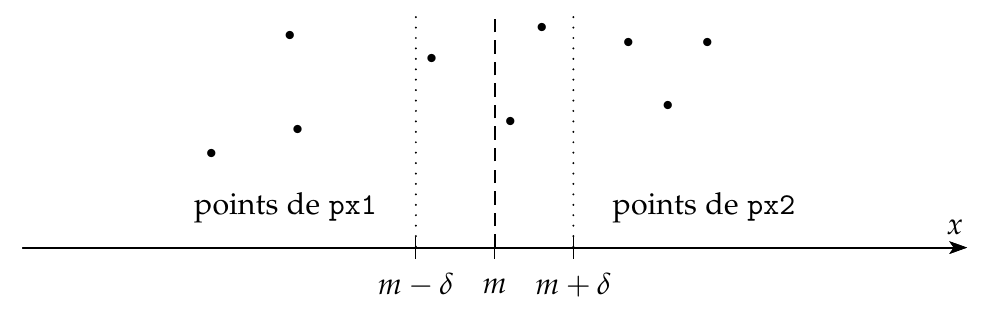
>
> En sélectionnant les points du tableau `py` dont les abscisses sont comprises entre $m - \delta$ et $m + \delta$, il ne reste plus qu'à faire la remarque cruciale suivante : la différence entre les ordonnées des éléments d'indice $i + 7$ et d'indice $i$ est supérieure à $\delta$.
>
> (a) Écrire une fonction `get_sorted(pts)` qui renvoie les tableaux triés `px` et `py`.
> (b) Écrire une fonction récursive `shortest_distance_dac` qui prend en argument `px` et `py`, et met en œuvre la méthode proposée ci-dessus (`dac` : *divide and conquer*).
> (c) La fonction obtenue est-elle plus performante que la fonction `shortest_distance_bf` ?
> Optimiser l'implémentation pour que ce soit bien le cas.

## 3 (a)

#### ✅ RÉSOLUTION

In [4]:
def get_sorted(pts):
    px = sorted(pts, key=lambda p: p[0])
    py = sorted(pts, key=lambda p: p[1])
    return px, py


px, py = get_sorted([(3, 1), (1, 5), (2, 2)])
print(px, py)

[(1, 5), (2, 2), (3, 1)] [(3, 1), (2, 2), (1, 5)]


#### 💡 EXPLICATION PÉDAGOGIQUE

`sorted` avec le paramètre `key` permet de choisir **selon quoi** on trie : `key=lambda p: p[0]` trie selon l'abscisse, `key=lambda p: p[1]` selon l'ordonnée.

## 3 (b) — une première version directe

#### ✅ RÉSOLUTION

In [5]:
def shortest_distance_dac_v1(px, py):
    n = len(px)
    if n <= 3:
        return shortest_distance_bf(px)
    milieu = n // 2
    px1, px2 = px[:milieu], px[milieu:]
    m = (px1[-1][0] + px2[0][0]) / 2
    py1 = sorted(px1, key=lambda p: p[1])          # on retrie à chaque appel...
    py2 = sorted(px2, key=lambda p: p[1])
    d1 = shortest_distance_dac_v1(px1, py1)
    d2 = shortest_distance_dac_v1(px2, py2)
    delta = min(d1, d2)
    bande = [p for p in py if m - delta <= p[0] <= m + delta]
    return min(delta, shortest_distance_bf(bande))  # ... et on compare TOUS les couples de la bande


nb_appels = 0
debut = time.time()
d = shortest_distance_dac_v1(*get_sorted(points))
print(f"{d:.2f}  |  appels : {nb_appels}  |  {time.time() - debut:.3f} s  |  identique à bf : {d == d_bf}")

1251419.02  |  appels : 11966  |  0.006 s  |  identique à bf : True


#### 💡 EXPLICATION PÉDAGOGIQUE

**Rappel du principe :**
1. on coupe `px` en deux moitiés `px1` (gauche) et `px2` (droite) ;
2. récursivement : $d_1$ = plus petite distance à gauche, $d_2$ = à droite, et $\delta = \min(d_1, d_2)$ ;
3. il reste les couples **à cheval** (un point à gauche, un point à droite). Seuls les points dont l'abscisse est entre $m - \delta$ et $m + \delta$ peuvent faire mieux que $\delta$ : c'est la **bande**.

**Cette première version traduit le principe tel quel :**
- **cas de base** : avec 3 points ou moins, on utilise la force brute (au plus 3 appels) ;
- pour obtenir `py1` et `py2`, on **retrie** `px1` et `px2` ;
- dans la bande, on compare **tous les couples**.

## 3 (c) — est-elle plus performante ? Optimisation

*Test sur des points presque alignés verticalement :*

In [6]:
seed(1)
verticaux = [(random(), random()*10**9) for _ in range(1500)]   # abscisses entre 0 et 1 seulement

for nom, f in [("force brute", lambda: shortest_distance_bf(verticaux)),
               ("dac v1", lambda: shortest_distance_dac_v1(*get_sorted(verticaux)))]:
    nb_appels = 0
    debut = time.time()
    f()
    print(f"{nom:>12} : {nb_appels:>8} appels  |  {time.time() - debut:.2f} s")

 force brute :  1124250 appels  |  0.25 s


      dac v1 :  2240360 appels  |  0.61 s


#### ✅ RÉSOLUTION

**Non, pas toujours.** Sur des points bien répartis, la version directe est déjà rapide. Mais si tous les points ont presque la même abscisse, **tous** tombent dans la bande, et comparer tous les couples de la bande coûte $n^2$, comme la force brute (test ci-dessus).

**Version optimisée :**

In [7]:
def shortest_distance_dac(px, py):
    n = len(px)
    if n <= 3:
        return shortest_distance_bf(px)
    milieu = n // 2
    px1, px2 = px[:milieu], px[milieu:]
    m = (px1[-1][0] + px2[0][0]) / 2

    # py1 et py2 en un seul parcours de py (qui est déjà trié par ordonnée)
    gauche = set(px1)
    py1, py2 = [], []
    for p in py:
        if p in gauche:
            py1.append(p)
        else:
            py2.append(p)

    delta = min(shortest_distance_dac(px1, py1), shortest_distance_dac(px2, py2))

    # la bande, déjà triée par ordonnée puisqu'on la prend dans py
    bande = [p for p in py if m - delta <= p[0] <= m + delta]
    for i in range(len(bande)):
        for k in range(i + 1, min(i + 8, len(bande))):     # au plus 7 voisins
            d = distance(bande[i], bande[k])
            if d < delta:
                delta = d
    return delta


for nom, pts in [("points aléatoires", points), ("points verticaux", verticaux)]:
    nb_appels = 0
    debut = time.time()
    d = shortest_distance_dac(*get_sorted(pts))
    print(f"{nom:>18} : {nb_appels:>6} appels  |  {time.time() - debut:.3f} s  |  "
          f"correct : {d == shortest_distance_bf(pts)}")

 points aléatoires :  10597 appels  |  0.005 s  |  correct : True


  points verticaux :  81984 appels  |  0.024 s  |  correct : True


*Vérification et comparaison des temps (non demandées) :*

In [8]:
# Vérification sur 300 petits nuages de points
for essai in range(300):
    pts = [(random()*100, random()*100) for _ in range(2 + essai % 40)]
    assert shortest_distance_dac(*get_sorted(pts)) == shortest_distance_bf(pts)
print("300 tests réussis ✔\n")

print(f"{'n':>7} | {'force brute':>11} | {'dac optimisée':>13}")
for n in [500, 1000, 2000, 20000, 100000]:
    pts = [(random()*10**9, random()*10**9) for _ in range(n)]
    if n <= 2000:
        debut = time.time()
        shortest_distance_bf(pts)
        t_bf = f"{time.time() - debut:.3f} s"
    else:
        t_bf = "trop long"
    debut = time.time()
    shortest_distance_dac(*get_sorted(pts))
    print(f"{n:>7} | {t_bf:>11} | {time.time() - debut:>11.3f} s")

300 tests réussis ✔

      n | force brute | dac optimisée
    500 |     0.032 s |       0.002 s


   1000 |     0.126 s |       0.005 s


   2000 |     0.512 s |       0.011 s
  20000 |   trop long |       0.161 s


 100000 |   trop long |       1.251 s


#### 💡 EXPLICATION PÉDAGOGIQUE

**Les deux défauts de la première version :**
1. **Le pire cas :** si tous les points sont dans la bande, on compare tous leurs couples : coût $n^2$.
2. **Les tris répétés :** retrier `px1` et `px2` à chaque appel coûte $n\log(n)$ par niveau, alors qu'on a déjà `py`.

**Les deux optimisations :**
1. **La remarque cruciale de l'énoncé :** dans la bande triée par ordonnée, l'élément d'indice $i+7$ a une ordonnée supérieure de plus de $\delta$ à celle de l'élément $i$. Il est donc **inutile** d'aller plus loin : on compare chaque point avec **au plus 7 voisins**. La bande coûte alors au plus $7n$ appels au lieu de $n^2$. (On va jusqu'à $i+7$ inclus, par sécurité en cas d'égalité.)
2. **Ne plus retrier :** pour construire `py1` et `py2`, on **parcourt `py` une seule fois** (qui est déjà trié) et on range chaque point à gauche ou à droite. Pour savoir rapidement si un point est dans `px1`, on utilise un **ensemble** (`set`) : le test `p in ensemble` est quasi instantané. Coût : $n$ par appel au lieu de $n\log(n)$.

Le coût total devient $n\log(n)$ : $\log(n)$ niveaux, avec un travail de l'ordre de $n$ à chaque niveau, exactement comme le tri fusion.

⚠️ La séparation avec un `set` suppose que **tous les points sont distincts**, ce qui est le cas avec des coordonnées tirées au hasard. Avec des doublons, la distance minimale vaut 0 et on peut la détecter à part.

**À retenir :**
- Force brute : $\dfrac{n(n-1)}{2}$ appels, donc un coût en $n^2$.
- « Diviser pour régner » bien implémenté : coût en $n\log(n)$. Avec 100 000 points, la force brute demanderait environ 5 milliards d'appels à `distance` !
- Une idée « diviser pour régner » ne suffit pas : **l'étape de combinaison** (ici la bande) doit coûter au plus $n$ à chaque niveau. Sinon, on perd tout le gain.